In [1]:
# =========================
# Imports
# =========================

# --- Standard library ---
import base64
import json
import os
import re
from datetime import datetime
from io import BytesIO

# --- Third-party ---
import requests
import openai
from PIL import Image
from dotenv import load_dotenv
from IPython.display import Markdown, display
import aisuite

# --- Local / project ---
import tools
import utils


# =========================
# Environment & Client
# =========================
load_dotenv()
client = aisuite.Client()


In [2]:
tools.tavily_search_tool('trends in sunglasses fashion')

[{'title': 'Sunglasses Trends 2026',
  'content': 'Sunglasses in 2026 reflect a perfect balance between statement aesthetics and enduring design. Bold frames, sculptural silhouettes, and retro influences lead the trends, with gradient lenses and metal shades taking center stage.\n\nSome styles of sunglasses are always in. Think sleek aviators, refined cat-eye frames, and classic square sunglasses. These iconic shapes transcend trends and continue to define modern elegance, season after season. [...] Timeless sunglasses combine minimal design with lasting impact. Think classic tortoiseshells, black frames, and metallic silhouettes. Whether you prefer a vintage or modern aesthetic, our timeless sunglasses collection offers styles that will never go out of style. [...] Square and oval sunglasses top the list when it comes to versatility. Their balanced lines suit a variety of face shapes, making them a staple for everyday styling.   \nFind your perfect versatile pair in our designer sungl

In [3]:
tools.product_catalog_tool()

[{'name': 'Aviator',
  'item_id': 'SG001',
  'description': 'Originally designed for pilots, these teardrop-shaped lenses with thin metal frames offer timeless appeal. The large lenses provide excellent coverage while the lightweight construction ensures comfort during long wear.',
  'quantity_in_stock': 23,
  'price': 103},
 {'name': 'Wayfarer',
  'item_id': 'SG002',
  'description': 'Featuring thick, angular frames that make a statement, these sunglasses combine retro charm with modern edge. The rectangular lenses and sturdy acetate construction create a confident look.',
  'quantity_in_stock': 6,
  'price': 92},
 {'name': 'Mystique',
  'item_id': 'SG003',
  'description': 'Inspired by 1950s glamour, these frames sweep upward at the outer corners to create an elegant, feminine silhouette. The subtle curves and often embellished temples add sophistication to any outfit.',
  'quantity_in_stock': 3,
  'price': 88},
 {'name': 'Sport',
  'item_id': 'SG004',
  'description': 'Designed for 

In [4]:
def market_research_agent(return_messages: bool = False):

    utils.log_agent_title_html("Market Research Agent", "🕵️‍♂️")

    prompt_ = f"""
You are a fashion market research agent tasked with preparing a trend analysis for a summer sunglasses campaign.

Your goal:
1. Explore current fashion trends related to sunglasses using web search.
2. Review the internal product catalog to identify items that align with those trends.
3. Recommend one or more products from the catalog that best match emerging trends.
4. If needed, today date is {datetime.now().strftime("%Y-%m-%d")}.

You can call the following tools:
- tavily_search_tool: to discover external web trends.
- product_catalog_tool: to inspect the internal sunglasses catalog.

Once your analysis is complete, summarize:
- The top 2–3 trends you found.
- The product(s) from the catalog that fit these trends.
- A justification of why they are a good fit for the summer campaign.
"""
    messages = [{"role": "user", "content": prompt_}]
    tools_ = tools.get_available_tools()

    while True:
        response = client.chat.completions.create(
            model="openai:o4-mini",
            messages=messages,
            tools=tools_,
            tool_choice="auto",
            max_completion_tokens=16000,  # reasoning models need room for reasoning + output
        )

        msg = response.choices[0].message

        if msg.content:
            utils.log_final_summary_html(msg.content)
            return (msg.content, messages) if return_messages else msg.content

        if msg.tool_calls:
            for tool_call in msg.tool_calls:
                utils.log_tool_call_html(tool_call.function.name, tool_call.function.arguments)
                result = tools.handle_tool_call(tool_call)
                utils.log_tool_result_html(result)

                messages.append(msg)
                messages.append(tools.create_tool_response_message(tool_call, result))
        else:
            utils.log_unexpected_html()
            return ("[⚠️ Unexpected: No tool_calls or content returned]", messages) if return_messages else "[⚠️ Unexpected: No tool_calls or content returned]"

In [5]:
market_research_result = market_research_agent()

In [6]:
import base64

def graphic_designer_agent(trend_insights: str, caption_style: str = "short punchy", size: str = "1024x1024") -> dict:
    utils.log_agent_title_html("Graphic Designer Agent", "🎨")

    # Step 1: Generate prompt and caption using aisuite
    system_message = (
        "You are a visual marketing assistant. Based on the input trend insights, "
        "write a creative and visual prompt for an AI image generation model, and also a short caption."
    )
    user_prompt = f"""
Trend insights:
{trend_insights}
Please output:
1. A vivid, descriptive prompt to guide image generation.
2. A marketing caption in style: {caption_style}.
Respond in this format:
{{"prompt": "...", "caption": "..."}}
"""
    chat_response = client.chat.completions.create(
        model="openai:o4-mini",
        messages=[
            {"role": "system", "content": system_message},
            {"role": "user", "content": user_prompt}
        ],
        max_completion_tokens=16000,  # reasoning models need room for reasoning + output
    )
    raw = chat_response.choices[0].message.content
    if not raw:
        raise RuntimeError(
            "Graphic designer model returned empty response "
            f"(finish_reason={chat_response.choices[0].finish_reason!r})."
        )
    content = raw.strip()
    match = re.search(r'\{.*\}', content, re.DOTALL)
    parsed = json.loads(match.group(0)) if match else {"error": "No JSON returned", "raw": content}
    prompt = parsed["prompt"]
    caption = parsed["caption"]

    # Step 2: Generate image with gpt-image-1-mini (returns base64, not URL)
    openai_client = openai.OpenAI()
    image_response = openai_client.images.generate(
        model="gpt-image-1-mini",
        prompt=prompt,
        size=size,
        quality="medium",   # gpt-image-1 accepts: low | medium | high | auto
        n=1,
        # no response_format — gpt-image-1 always returns b64_json
    )

    b64 = image_response.data[0].b64_json
    img_bytes = base64.b64decode(b64)
    img = Image.open(BytesIO(img_bytes))

    image_path = "generated_image.png"
    img.save(image_path)

    # Show the generated image inline, then log prompt + caption as plain text
    from IPython.display import Image as IPyImage
    display(IPyImage(filename=image_path, width=512))
    utils.log_final_summary_html(
        f"Image path: {image_path}\n\nCaption: {caption}\n\nPrompt: {prompt}"
    )

    return {
        "image_path": image_path,
        "prompt": prompt,
        "caption": caption,
    }

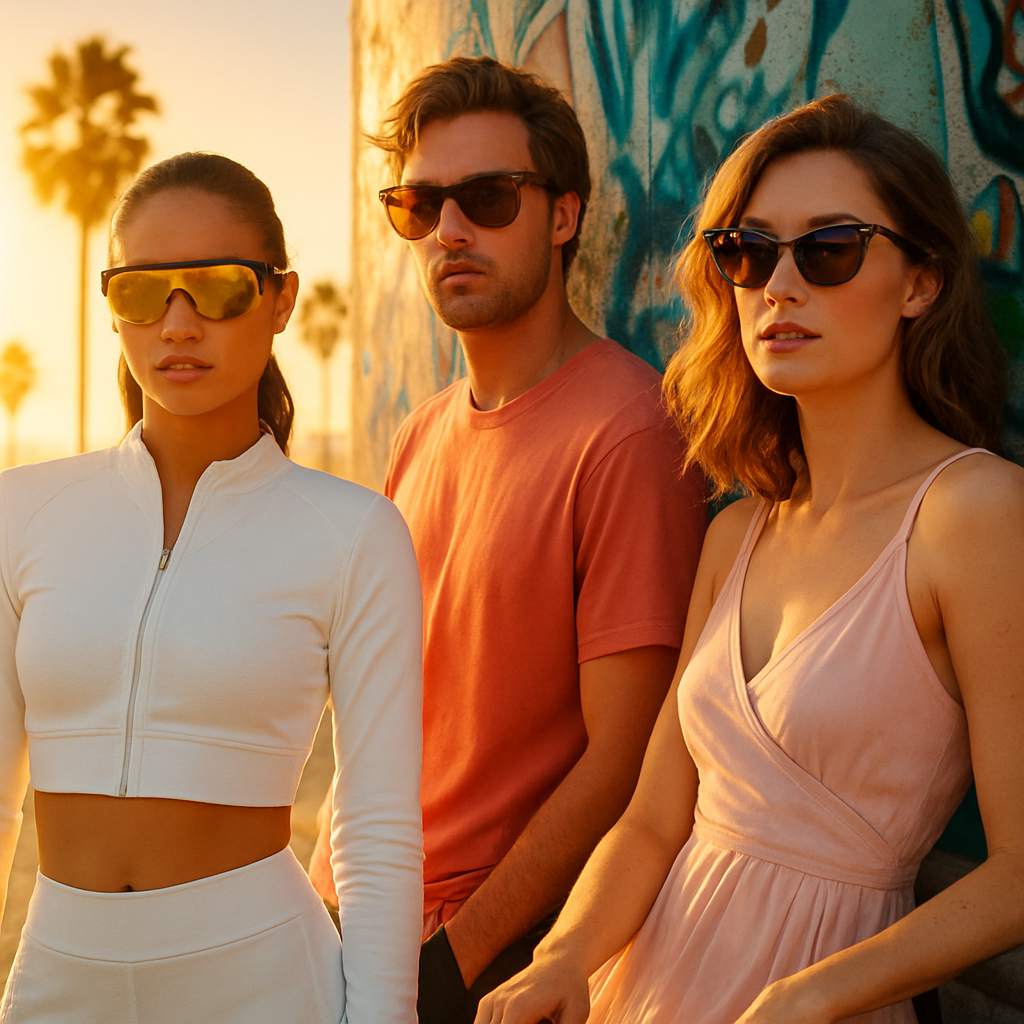

In [7]:
graphic_designer_agent_result = graphic_designer_agent(
    trend_insights=market_research_result,
)


In [8]:
def copywriter_agent(image_path: str, trend_summary: str, model: str = "openai:o4-mini") -> dict:

    """
    Uses aisuite (OpenAI only) to send an image and a trend summary and return a campaign quote.

    Args:
        image_path (str): Local path of the image to be analyzed.
        trend_summary (str): Text from the researcher agent.
        model (str): OpenAI model (e.g., openai:o4-mini, openai:gpt-4o)

    Returns:
        dict: {
            "quote": "...",
            "justification": "...",
            "image_path": "..."
        }
    """

    utils.log_agent_title_html("Copywriter Agent", "✍️")

    # Step 1: Load local image and encode as base64
    with open(image_path, "rb") as f:
        img_bytes = f.read()

    b64_img = base64.b64encode(img_bytes).decode("utf-8")

    # Step 2: Build OpenAI-compliant multimodal message
    messages = [
        {
            "role": "system",
            "content": "You are a copywriter that creates elegant campaign quotes based on an image and a marketing trend summary."
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/png;base64,{b64_img}",
                        "detail": "auto"
                    }
                },
                {
                    "type": "text",
                    "text": f"""
Here is a visual marketing image and a trend analysis:

Trend summary:
\"\"\"{trend_summary}\"\"\"

Please return a JSON object like:
{{
  "quote": "A short, elegant campaign phrase (max 12 words)",
  "justification": "Why this quote matches the image and trend"
}}"""
                }
            ]
        }
    ]

    # Step 3: Send request via aisuite
    # Reasoning models (o1/o3/o4) need extra budget so they have room left
    # for the visible JSON output after their internal reasoning tokens.
    extra = {"max_completion_tokens": 16000} if model.startswith(("openai:o1", "openai:o3", "openai:o4")) else {}
    response = client.chat.completions.create(
        model=model,
        messages=messages,
        **extra,
    )

    # Step 4: Parse JSON response
    raw = response.choices[0].message.content
    if not raw:
        raise RuntimeError(
            "Copywriter model returned empty response "
            f"(finish_reason={response.choices[0].finish_reason!r})."
        )
    content = raw.strip()

    utils.log_final_summary_html(content)

    try:
        match = re.search(r'\{.*\}', content, re.DOTALL)
        parsed = json.loads(match.group(0)) if match else {"error": "No valid JSON returned"}
    except Exception as e:
        parsed = {"error": f"Failed to parse: {e}", "raw": content}


    parsed["image_path"] = image_path
    return parsed


In [9]:
copywriter_agent_result = copywriter_agent(
    image_path=graphic_designer_agent_result["image_path"],
    trend_summary=market_research_result,
)

In [10]:
def packaging_agent(trend_summary: str, image_url: str, quote: str, justification: str, output_path: str = "campaign_summary.md") -> str:

    """
    Packages the campaign assets into a beautifully formatted markdown report for executive review.

    Args:
        trend_summary (str): Summary of the market trends.
        image_url (str): URL of the campaign image.
        quote (str): Marketing quote to overlay.
        justification (str): Explanation for the quote.
        output_path (str): Path to save the markdown report.

    Returns:
        str: Path to the saved markdown file.
    """

    utils.log_agent_title_html("Packaging Agent", "📦")

    # Embed the image as base64 so the markdown renders in the notebook and
    # the report is self-contained (a relative path would not load in JupyterLab).
    try:
        with open(image_url, "rb") as _f:
            _b64 = base64.b64encode(_f.read()).decode("utf-8")
        styled_image_html = f"![Campaign visual](data:image/png;base64,{_b64})"
    except Exception:
        styled_image_html = f"![Campaign visual]({image_url})"

    _resp_summary = client.chat.completions.create(
        model="openai:o4-mini",
        messages=[
            {"role": "system", "content": "You are a marketing communication expert writing elegant campaign summaries for executives."},
            {"role": "user", "content": f"""
Please rewrite the following trend summary to be clear, professional, and engaging for a CEO audience:

\"\"\"{trend_summary.strip()}\"\"\"
"""}
        ],
        max_completion_tokens=16000,
    )
    _raw_summary = _resp_summary.choices[0].message.content
    if not _raw_summary:
        # Reasoning model exhausted its budget. Fall back to the original
        # trend_summary so we can still produce the campaign report.
        beautified_summary = trend_summary.strip()
    else:
        beautified_summary = _raw_summary.strip()

    utils.log_tool_result_html(beautified_summary)

    # Combine all parts into markdown
    markdown_content = f"""# 🕶️ Summer Sunglasses Campaign – Executive Summary

## 📊 Refined Trend Insights
{beautified_summary}

## 🎯 Campaign Visual
{styled_image_html}

## ✍️ Campaign Quote
{quote.strip()}

## ✅ Why This Works
{justification.strip()}

---

*Report generated on {datetime.now().strftime('%Y-%m-%d')}*
"""

    with open(output_path, "w", encoding="utf-8") as f:
        f.write(markdown_content)

    return output_path



In [11]:
packaging_agent_result = packaging_agent(
    trend_summary=market_research_result,
    image_url=graphic_designer_agent_result["image_path"],
    quote=copywriter_agent_result["quote"],
    justification=copywriter_agent_result["justification"],
    output_path=f"campaign_summary_{datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.md"
)

# 🕶️ Summer Sunglasses Campaign – Executive Summary

## 📊 Refined Trend Insights
Summer 2026 Sunglasses Campaign Executive Summary  
Date: October 15, 2026

Key Market Trends  
• Performance­-Meets­-Streetwear Shields  
  ­ Oversized, single-­lens “shield” and wrap-­around silhouettes blend athletic function with urban style.  
• Statement­-Making Acetate  
  ­ Chunky, angular frames (oversized aviators, bold wayfarers) deliver unmistakable visual impact.  
• Elevated Retro Details  
  ­ Ornamental temples (rhinestones, metal accents) and ’50s/’90s cat-eye revivals introduce a refined, collectible feel.

Product Alignment  
• SG004 “Sport” Shield  
  ­ Lightweight, flexible frame with rubber grips and a continuous curved lens—perfectly captures the performance­-streetwear crossover.  
• SG002 Chunky Wayfarer  
  ­ Thick acetate construction in a unisex, design­-forward profile, catering to consumers seeking both durability and style.  
• SG003 “Mystique” Cat-Eye  
  ­ Upturned corners with subtle temple embellishments—an on-trend nod to vintage glamour and high­-end detailing.

Strategic Rationale  
• Broad Consumer Appeal  
  ­ Sports­-inspired shields engage athleisure and fashion­-forward buyers.  
  ­ Bold wayfarers satisfy mass­-market demand for versatile, unisex eyewear.  
  ­ Embellished cat-­eyes attract luxury and statement­-piece shoppers.  
• On­-Trend Relevance  
  ­ Each style embodies a core Summer 2026 insight—functionality, boldness, or elevated ornamentation—ensuring resonance across segments.  
• Inventory & Pricing Advantage  
  ­ Adequate stock levels (SG004: 11 units; SG002: 6 units; SG003: 3 units) and accessible price points ($88–$144) support flexible promotional strategies.

Recommendation  
Feature all three silhouettes as cornerstones of the Summer 2026 campaign. This balanced portfolio—spanning high-­performance shields, bold acetates, and luxe cat­-eyes—will maximize market reach, reinforce our trend leadership, and drive both volume and margin objectives.

## 🎯 Campaign Visual
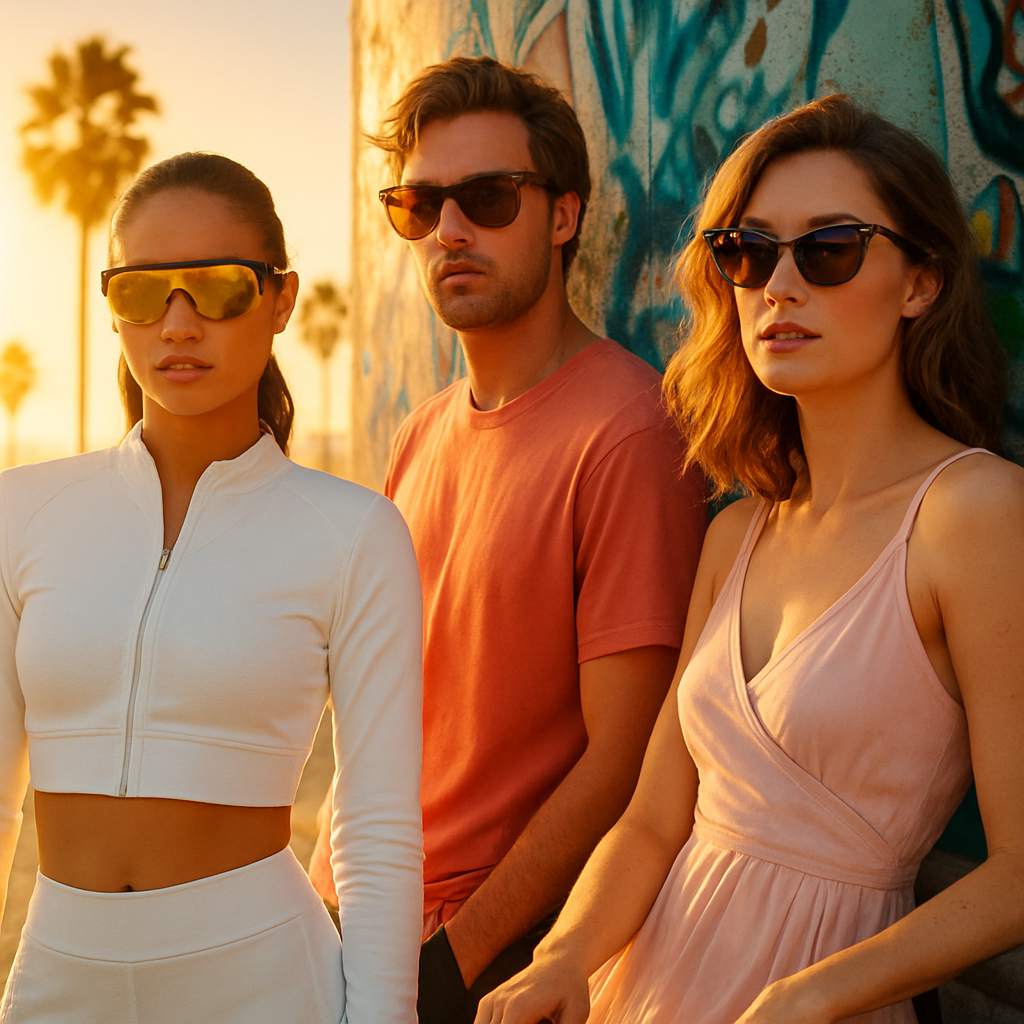

## ✍️ Campaign Quote
Capture Summer’s Glow: Sport Shield, Bold Acetate, Elegant Cat-Eye

## ✅ Why This Works
This line spotlights the three core 2026 trends—performance-driven shields, statement-making acetate, and retro-inspired cat-eyes—while echoing the image’s golden-hour palette and the models’ dynamic mix of sporty, bold, and ornamental styles.

---

*Report generated on 2026-10-15*


In [12]:
# Load and render the markdown content
with open(packaging_agent_result, "r", encoding="utf-8") as f:
    md_content = f.read()

display(Markdown(md_content))


In [13]:
def run_sunglasses_campaign_pipeline(output_path: str = "campaign_summary.md") -> dict:
    """
    Runs the full summer sunglasses campaign pipeline:
    1. Market research (search trends + match products)
    2. Generate visual + caption
    3. Generate quote based on image + trend
    4. Create executive markdown report

    Returns:
        dict: Dictionary containing all intermediate results + path to final report
    """
    # 1. Run market research agent
    trend_summary = market_research_agent()
    print("✅ Market research completed")

    # 2. Generate image + caption
    visual_result = graphic_designer_agent(trend_insights=trend_summary)
    image_path = visual_result["image_path"]
    print("🖼️ Image generated")

    # 3. Generate quote based on image + trends
    quote_result = copywriter_agent(image_path=image_path, trend_summary=trend_summary)
    quote = quote_result.get("quote", "")
    justification = quote_result.get("justification", "")
    print("💬 Quote created")

    # 4. Generate markdown report
    md_path = packaging_agent(
        trend_summary=trend_summary,
        image_url=image_path,  
        quote=quote,
        justification=justification,
        output_path=f"campaign_summary_{datetime.now().strftime('%Y-%m-%d_%H-%M-%S')}.md"
    )

    print(f"📦 Report generated: {md_path}")

    return {
        "trend_summary": trend_summary,
        "visual": visual_result,
        "quote": quote_result,
        "markdown_path": md_path
    }


✅ Market research completed


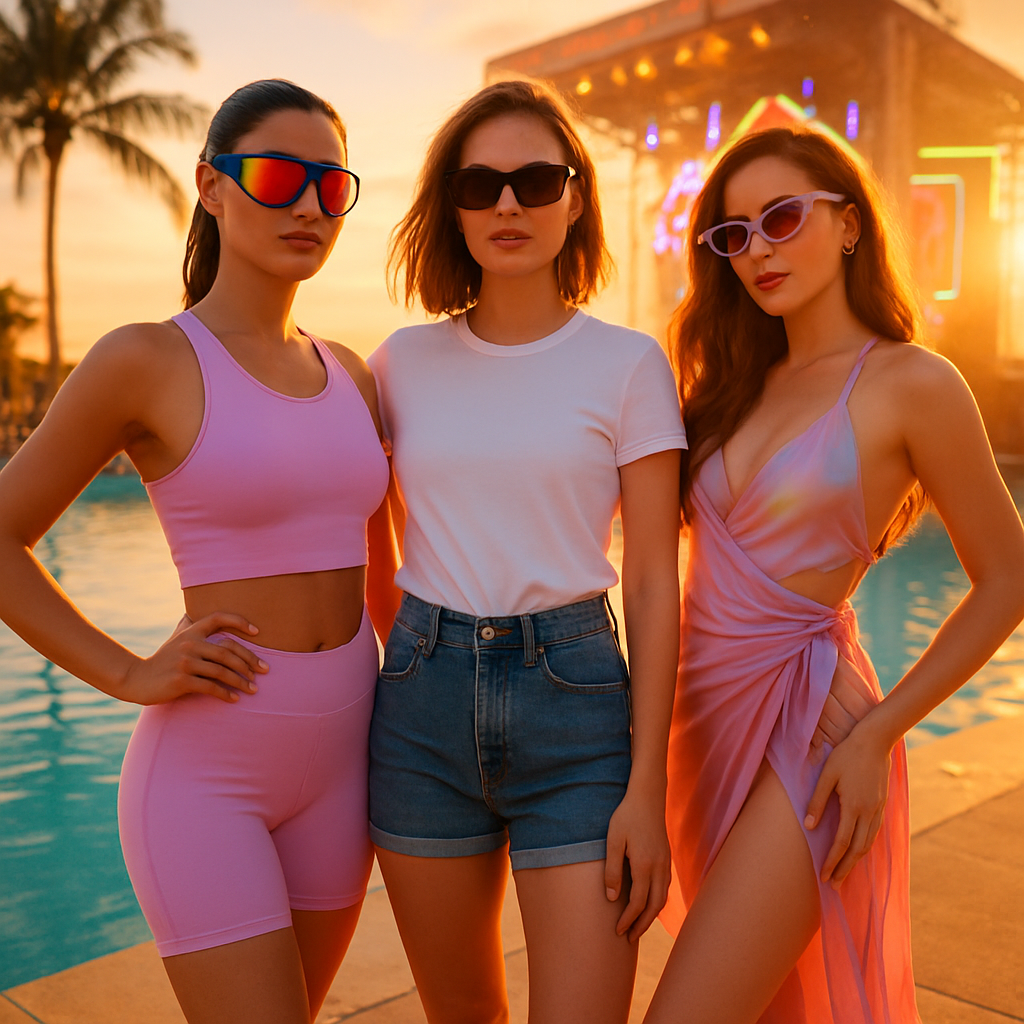

🖼️ Image generated


💬 Quote created


📦 Report generated: campaign_summary_2026-10-15_05-55-25.md


In [14]:
results = run_sunglasses_campaign_pipeline()

# 🕶️ Summer Sunglasses Campaign – Executive Summary

## 📊 Refined Trend Insights
Executive Summary  
For Summer 2026, three distinct eyewear movements will dominate—and our existing catalog perfectly aligns with each. By leaning into these trends, we position our brand as both runway-relevant and consumer-ready, maximizing social buzz and sales velocity.

1. Trend: Oversized Shields & Sporty Wrap-arounds  
   • Market Insight: Single-lens, curved silhouettes marry high-performance utility with futuristic styling—ideal for athleisure, poolside lounging or festival goers.  
   • Our Match: SG004 “Sport” Wraparound  
     – Features full-coverage single-lens construction, non-slip rubber grips and a seamless, sleek profile.  
     – Business Impact: Appeals to active-lifestyle shoppers and influencers alike, driving aspirational imagery and repeat engagement.

2. Trend: Chunky Acetate & Retro-Inspired Shapes  
   • Market Insight: Bold, thick-frame Wayfarers, cat-eyes and butterfly profiles are resurging as statement pieces that blend vintage nostalgia with modern edge.  
   • Our Match: SG002 “Wayfarer” Thick Acetate  
     – Delivers a commanding angular silhouette in premium acetate.  
     – Business Impact: Universally flattering design reduces return rates, accelerates word-of-mouth and underpins premium price positioning.

3. Trend: Tinted & Gradient Lenses  
   • Market Insight: Soft color washes—from amber and rose to lavender—or dual-tone gradients infuse a playful, retro-luxe dimension.  
   • Our Match: SG003 “Mystique” Cat-Eye with Embellished Temples  
     – Combines an upswept, feminine frame with subtle metallic temple accents.  
     – Business Impact: Ideal for lifestyle and fashion shoots, driving aspirational content that resonates across day-to-night wardrobes.

Why These Styles Win This Summer  
   • High Visual Impact: Each frame is instantly “Instagrammable,” producing content that performs on social channels.  
   • Broad Appeal & Versatility: From performance-driven athleisure to elevated evening attire, these styles capture multiple consumer segments.  
   • Authentic Trend Alignment: By tapping runway-to-street currents—futuristic shields, chunky retro shapes and decorative lenses—we reinforce our summer line as both current and covetable.

## 🎯 Campaign Visual
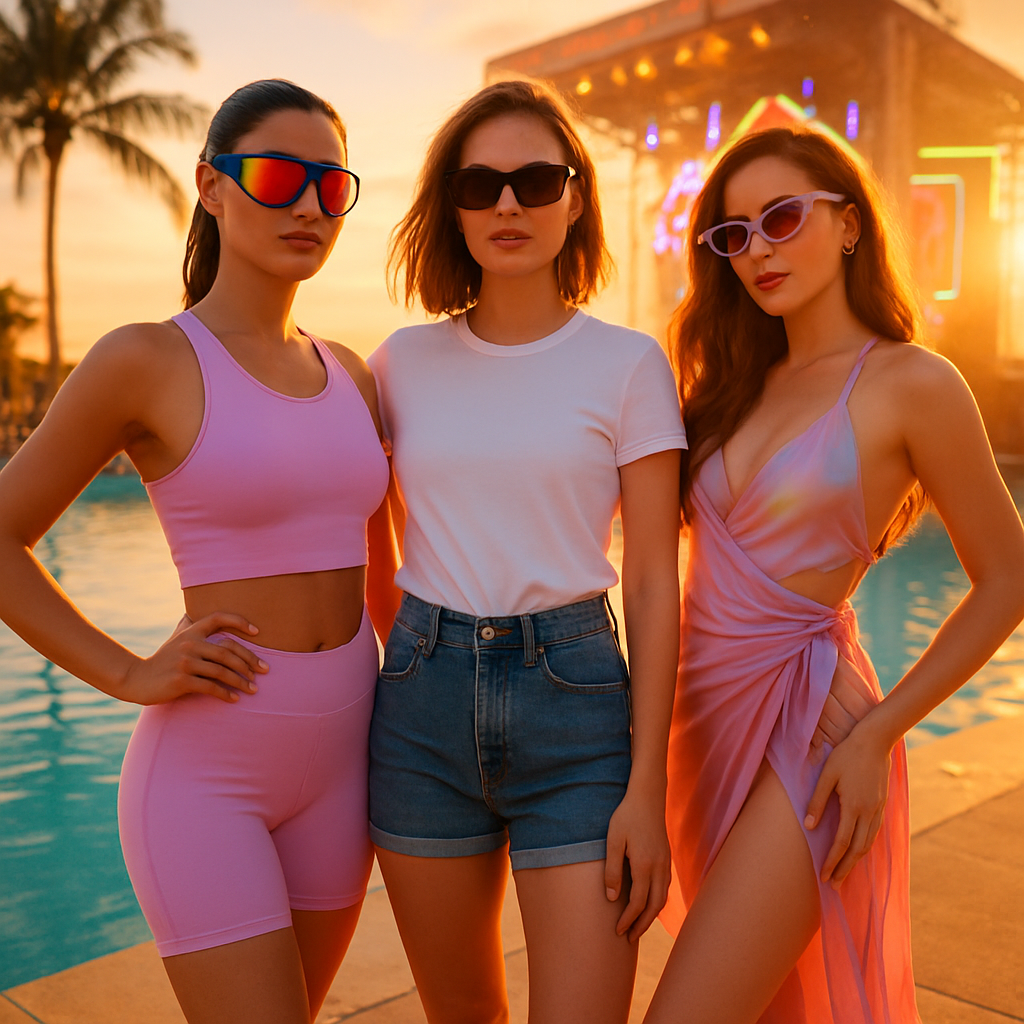

## ✍️ Campaign Quote
Sunset Shields: Sporty Edge Meets Retro Glam

## ✅ Why This Works
The phrase captures the image’s golden-hour poolside vibe and highlights our top summer ’26 trends: the futuristic wraparound ‘sport’ shield, chunky acetate Wayfarer attitude, and cat-eye ‘Mystique’ glamour in one elegant line.

---

*Report generated on 2026-10-15*


In [15]:
with open(results["markdown_path"], "r", encoding="utf-8") as f:
    md_content = f.read()
display(Markdown(md_content))
